# UCI HAR 探索性分析

30 人×6 活動×50Hz——訊號長相、活動間的可分性、受試者變異。

**這本 notebook 回答三個問題**（對應 `reports/findings.md` 的三個發現）：

1. 原始訊號長什麼樣？動態活動（走/跑/樓梯）與靜態活動（坐/站/躺）肉眼可分嗎？
2. 頻域裡的「步頻指紋」長什麼樣？——自製特徵的主力訊息來源
3. 受試者之間的變異有多大？——subject-wise CV 折間 86-98% 的原始素材


In [1]:

import sys; sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# dataviz 慣例（與 reports/figures 同一視覺系統）
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 10.5,
})

from src.isa.config import UCI_DIR, ACTIVITY_LABELS
from src.isa.data.loader import load_raw_signals, load_labels, load_subjects
from src.isa.features.freq_domain import dominant_frequency_hz

X = load_raw_signals(UCI_DIR, "train")          # (7352, 9, 128)
y = load_labels(UCI_DIR, "train")
subj = load_subjects(UCI_DIR, "train")

print(f"windows: {X.shape}, subjects(train): {len(np.unique(subj))}")
pd.DataFrame({"activity": [ACTIVITY_LABELS[a] for a in y]}).value_counts().rename("windows")


windows: (7352, 9, 128), subjects(train): 21


activity          
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: windows, dtype: int64

## 1. 訊號長相：一個人做六種活動

取一位受試者、每種活動各一個視窗（2.56s @50Hz），畫 total_acc 合成量
（含重力）。動態活動的規律振盪與靜態活動的近乎平坦，肉眼即可分——
**分類的難點從來不在動態 vs 靜態，而在靜態內部（坐 vs 站）**。


六活動全做的受試者：[1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]——示範取 S01


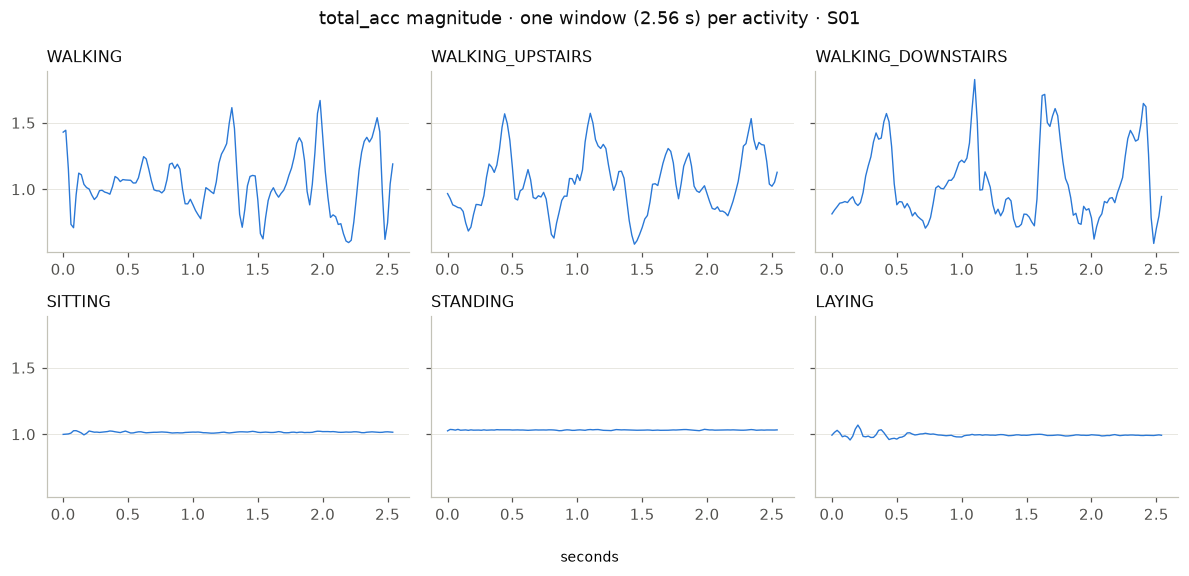

In [2]:
def acc_mag(w):
    return np.sqrt((w ** 2).sum(axis=0))

ids, counts = np.unique(subj, return_counts=True)
rich = [int(s) for s, c in zip(ids, counts, strict=True)
        if len(np.unique(y[subj == s])) == 6]
sid = rich[0]
print(f"六活動全做的受試者：{rich}——示範取 S{sid:02d}")

fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharey=True)
for ax, (code_a, name) in zip(axes.ravel(), sorted(ACTIVITY_LABELS.items()),
                              strict=True):
    w = X[np.flatnonzero((subj == sid) & (y == code_a))[0]]
    m = acc_mag(w[6:9, :])
    t = np.arange(len(m)) / 50
    ax.plot(t, m, lw=0.9, color=BLUE)
    ax.set_title(f"{name}", color=INK, loc="left")
    ax.grid(axis="y", lw=0.5, color=GRID)
    ax.set_axisbelow(True)
fig.suptitle(f"total_acc magnitude · one window (2.56 s) per activity · S{sid:02d}",
             color=INK, fontsize=11.5)
fig.supxlabel("seconds", fontsize=9)
fig.tight_layout()
plt.show()


## 2. 頻域的「步頻指紋」

對 total_acc 合成量做 FFT：走路在 1-3Hz（步頻帶）出現乾淨的主峰，
上樓梯把主頻推低、坐姿只剩雜訊——**自製頻域特徵（主頻/質心/頻帶能量/熵）
就是在量化這張圖**。動態活動的召回 ≥88% 由此而來。


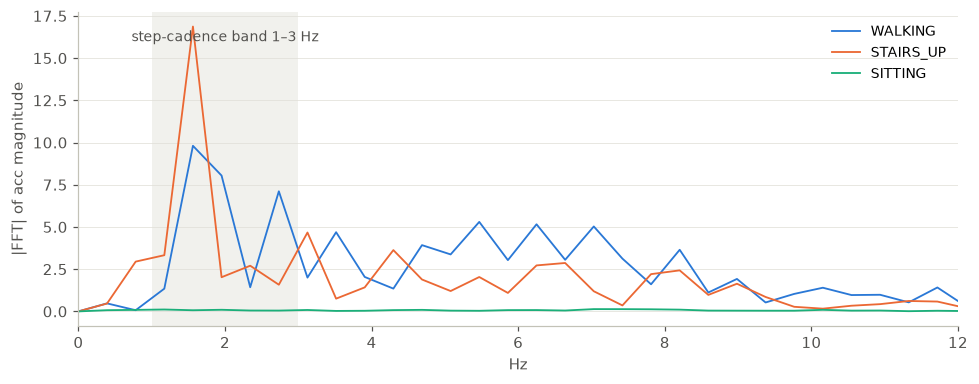

In [3]:
win = {n: X[np.flatnonzero((subj == sid) & (y == c))[0]]
       for c, n in [(1, "WALKING"), (2, "STAIRS_UP"), (4, "SITTING")]}

fig, ax = plt.subplots(figsize=(9, 3.6))
for (name, w), color in zip(win.items(), (BLUE, ORANGE, AQUA), strict=True):
    m = acc_mag(w[6:9, :])
    spec = np.abs(np.fft.rfft(m - m.mean()))
    freqs = np.fft.rfftfreq(len(m), d=1 / 50)
    ax.plot(freqs, spec, lw=1.2, color=color, label=name)
ax.set_xlabel("Hz"); ax.set_ylabel("|FFT| of acc magnitude")
ax.set_xlim(0, 12)
ax.axvspan(1, 3, color=GRID, alpha=0.45, lw=0, zorder=0)
ax.text(2.0, ax.get_ylim()[1] * 0.94, "step-cadence band 1–3 Hz",
        ha="center", va="top", fontsize=9, color=INK2)
ax.grid(axis="y", lw=0.5, color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()


## 3. 受試者變異：折間 86-98% 的原始素材

同樣是走路，每個人的步頻、幅度都不同——這是 subject-wise CV 折間準確率
從 86% 到 98% 的訊號層根源。左圖：每人貢獻的視窗數大致均衡（分層抽樣的
前提）；右圖：各受試者走路視窗的主頻分布——**離散度高的人，模型從未見過
的步態就越遠**。


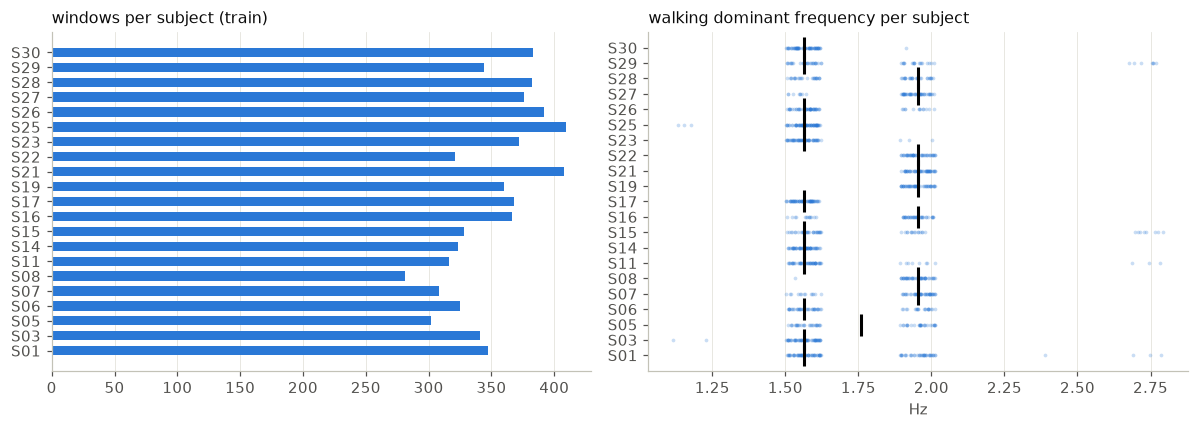

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

vc = pd.Series(subj).value_counts().sort_index()
ax1.barh([f"S{s:02d}" for s in vc.index], vc.values, height=0.62, color=BLUE)
ax1.set_title("windows per subject (train)", loc="left", color=INK)
ax1.grid(axis="x", lw=0.5, color=GRID); ax1.set_axisbelow(True)

walk_rows = []
for s in vc.index:
    idx = np.flatnonzero((subj == s) & (y == 1))
    for i in idx:
        m = acc_mag(X[i][6:9, :])
        walk_rows.append({"subject": f"S{s:02d}",
                          "domfreq": dominant_frequency_hz(m)})
wd = pd.DataFrame(walk_rows)
subjects = wd["subject"].unique()
rng = np.random.default_rng(0)
ax2.scatter(wd["domfreq"] + rng.uniform(-0.06, 0.06, len(wd)), wd["subject"],
            s=6, alpha=0.25, color=BLUE, linewidths=0)
med = wd.groupby("subject")["domfreq"].median()
ax2.plot(med.values, med.index, "k|", markersize=14, markeredgewidth=2)
ax2.set_title("walking dominant frequency per subject", loc="left", color=INK)
ax2.set_xlabel("Hz"); ax2.grid(axis="x", lw=0.5, color=GRID)
ax2.set_axisbelow(True)
fig.tight_layout()
plt.show()


## 小結

- 動態/靜態在時域肉眼可分；**靜態內部（坐 vs 站）才是瓶頸**——加速度幾乎
  無差，需要姿態幾何（重力向量）才拆得開（→ notebook 02）
- 頻域 1-3Hz 步頻帶是動態活動的指紋——自製頻域特徵的依據
- 受試者變異是真實的訊號層現象——部署到新使用者時，以折間變異而非平均
  預期表現（findings 第三節）
